<a href="https://colab.research.google.com/github/NastaranTork/stochastic-processes-lab/blob/main/03_renewal_bus_stop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Renewal processes, waiting at a bus stop

This notebook follows Notes 4 of IE 8532. The goal is to check the renewal reward theorem, the residual life result, and the inspection paradox by simulation, using buses arriving at a stop.

**Setting.** Buses arrive at a stop with iid headways $X$ and mean headway $\mu = 10$ minutes, so the arrivals form a renewal process. A passenger arrives at a random time far from the start.

**Contents**

1. Build the renewal process in the time frame
2. Part A. Expected wait of a random passenger
3. Part B. The inspection paradox
4. Part C. Renewal reward, cost per minute
5. Summary

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
rng = np.random.default_rng(8532)

MU = 10.0   # mean headway in minutes

# Three headway distributions, all with mean 10 minutes. Each takes (n, rng) and returns n headways.
headway = {
    "Deterministic 10":     lambda n, rng: np.full(n, 10.0),
    "Exponential, mean 10": lambda n, rng: rng.exponential(10.0, size=n),
    "Uniform(5, 15)":       lambda n, rng: rng.uniform(5.0, 15.0, size=n),
}

In [2]:
def simulate_renewal(sampler, T, rng):
    """Return (headways X, arrival times S) for a renewal process run up to at least time T."""
    clock = 0
    headways = []
    arrivals = []
    while True:
      headway = sampler(1, rng)[0]
      headways.append(headway)
      clock += headway
      arrivals.append(clock)
      if clock > T:
         break
    return np.array(headways), np.array(arrivals)

## Strong Law for renewal processes

**Proposition 2 (Strong Law for RPs).** Let $\{N(t), t \ge 0\}$ be a renewal process with iid inter-renewal times $X_1, X_2, \dots$ and mean $\mu = E[X_i]$, where $0 < \mu < \infty$. Then

$$\lim_{t \to \infty} \frac{N(t)}{t} = \frac{1}{\mu} \quad \text{almost surely.}$$

So $1/\mu$ is called the **rate** of the renewal process.

**What it means for the bus stop.** The long-run number of buses per minute is $1/\mu$, whatever the shape of the headway distribution. With $\mu = 10$ minutes, every distribution below should give a rate close to $0.1$ buses per minute, even though the three distributions behave very differently otherwise.

In [3]:
T = 1_000_000
for name, sampler in headway.items():
    X, S = simulate_renewal(sampler, T, rng)
    print(name, "| number of arrivals:", len(X), "| rate:", len(X)/T)


Deterministic 10 | number of arrivals: 100001 | rate: 0.100001
Exponential, mean 10 | number of arrivals: 99736 | rate: 0.099736
Uniform(5, 15) | number of arrivals: 100031 | rate: 0.100031


## Expected wait of a random passenger

The wait of a passenger who arrives at time $t$ is the **residual life** $Y(t) = S_{N(t)+1} - t$. This is the time from $t$ until the next bus.

In the long run, a passenger who arrives at a random time waits on average

$$\lim_{t\to\infty} E[Y(t)] = \frac{E[X^2]}{2\mu}.$$

Since $E[X^2] = \mu^2 + \sigma^2$, where $\sigma^2$ is the variance of the headway, this can be written as

$$\frac{E[X^2]}{2\mu} = \frac{\mu}{2} + \frac{\sigma^2}{2\mu}.$$

**How to read it.**
- The first term, $\mu/2$, is the wait if buses were perfectly regular. A passenger arrives on average halfway through a headway, so waits half of it.
- The second term, $\sigma^2/(2\mu)$, is the extra wait caused by irregular headways. It grows with the variance and is zero when every headway is the same.
- So two routes with the same average headway can give passengers very different waits. The route with the more variable headways is worse.

**Why variability hurts.** A random passenger is more likely to arrive during a long headway than a short one, because long headways cover more of the time axis. This is the inspection paradox. The passenger therefore tends to land in the long gaps, and long gaps mean long waits.

**What to expect here.** With $\mu = 10$ minutes, the formula predicts the following.

| Headway | $\sigma^2$ | Expected wait $E[X^2]/(2\mu)$ |
|---|---|---|
| Deterministic 10 | 0 | 5.00 |
| Exponential, mean 10 | 100 | 10.00 |
| Uniform(5, 15) | $100/12 \approx 8.33$ | 5.42 |

The simulation should reproduce these three numbers.

In [4]:
def passenger_waits(S, n_pass, t_lo, t_hi, rng):
    """Waits of n_pass passengers arriving uniformly in (t_lo, t_hi). Also return the index of the next bus."""
    t = rng.uniform(t_lo, t_hi, size=n_pass)
    idx = np.searchsorted(S, t)
    waits = S[idx] - t

    return waits, idx

EX2 = {"Deterministic 10": 100.0, "Exponential, mean 10": 200.0, "Uniform(5, 15)": 100.0 + 100.0/12}

T = 1_000_000
for name, sampler in headway.items():
    X, S = simulate_renewal(sampler, T, rng)
    waits, idx = passenger_waits(S, 200_000, 0.1*T, 0.9*T, rng)
    print(name, "| mean wait:", waits.mean(), "| EX2/2 * MU:", EX2[name]/20)


Deterministic 10 | mean wait: 4.99397662493266 | EX2/2 * MU: 5.0
Exponential, mean 10 | mean wait: 10.060696790628057 | EX2/2 * MU: 10.0
Uniform(5, 15) | mean wait: 5.432245437895545 | EX2/2 * MU: 5.416666666666666




---


## The inspection paradox

The headway that contains the passenger, $X_{N(t)+1}$, is longer on average than an ordinary headway. Its long-run mean is $E[X^2]/\mu$.

**Task.** For each distribution, estimate the average length of the headway the passenger lands in, and compare it with the mean headway of 10 and with $E[X^2]/\mu$.




In [5]:
for name, sampler in headway.items():
    X, S = simulate_renewal(sampler, T, rng)
    waits, idx = passenger_waits(S, 200_000, 0.1*T, 0.9*T, rng)
    contain = X[idx]                    # headway each passenger lands in, from X and idx
    print(name, "| mean containing headway:", contain.mean(), "| E[X^2]/MU:", EX2[name]/MU)


Deterministic 10 | mean containing headway: 10.0 | E[X^2]/MU: 10.0
Exponential, mean 10 | mean containing headway: 20.08034471570744 | E[X^2]/MU: 20.0
Uniform(5, 15) | mean containing headway: 10.830065178209384 | E[X^2]/MU: 10.833333333333332


**Expected wait.** All three routes have the same mean headway of 10 minutes, yet the average wait differs by a factor of two. The wait grows with the variability of the headway. It is 5 minutes when buses are perfectly regular, 5.4 when headways vary a little, and 10 when they are exponential.

**Inspection paradox.** With regular buses the passenger's headway equals the average headway of 10. With exponential headways it is about 20, twice the average, because long headways cover more of the clock and so catch more passengers.

**Takeaway.** Same average headway does not mean same experience. Headway variability raises both the wait and the length of the headway a rider experiences, and the renewal theory formulas predict both from the second moment $E[X^2]$ alone. For transit planning, reducing headway variability, as in bunching control, cuts waiting time without changing the average frequency.



---


## Limiting distribution of the wait

**Theorem (limiting distribution of residual life, slides 47 and 48).** Let $Y(t) = S_{N(t)+1} - t$ be the wait from time $t$ until the next renewal. If $F$ is not lattice and has finite mean $\mu$, then for every $x \ge 0$

$$\lim_{t\to\infty} P\big(Y(t) \le x\big) = \frac{1}{\mu}\int_0^x \big(1 - F(y)\big)\,dy.$$

**In our case.** This is the long-run chance that a passenger waits at most $x$ minutes.


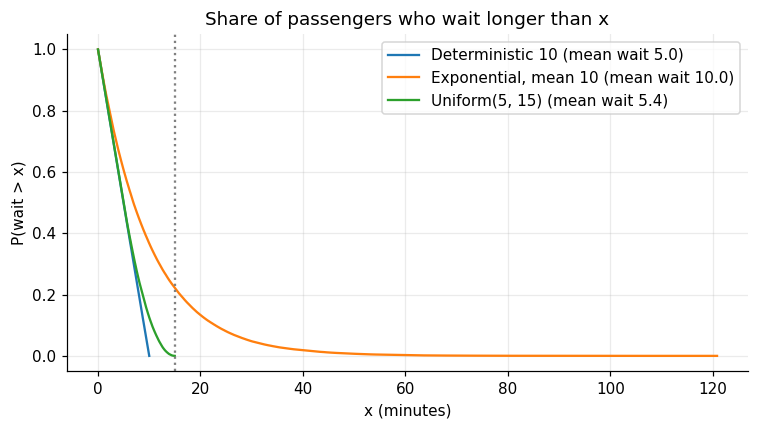

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

for name, sampler in headway.items():
    X, S = simulate_renewal(sampler, T, rng)
    waits, idx = passenger_waits(S, 200_000, 0.1*T, 0.9*T, rng)
    w = np.sort(waits)
    ax.plot(w, 1 - np.arange(1, len(w)+1)/len(w), label=f"{name} (mean wait {waits.mean():.1f})")

ax.axvline(15, color="gray", ls=":")
ax.set_xlabel("x (minutes)")
ax.set_ylabel("P(wait > x)")
ax.set_title("Share of passengers who wait longer than x")
ax.legend(); plt.tight_layout(); plt.show()

At $x = 15$ (the dotted line), the exponential curve is at about 0.22, while the other two are at 0. The deterministic and uniform routes never make anyone wait that long, but the exponential route does, even though all three have the same average headway.


---



## Renewal reward, cost per minute

Number the cycles $1, 2, 3, \dots$. Cycle $n$ is the gap between the $(n-1)$th and the $n$th bus, and its length is $X_n$. Each cycle earns a reward $R_n$, which may depend on its length. For example, $R_n = X_n^2$ is a crowding penalty that grows with the length of the gap.

Let $N(t)$ be the number of cycles completed by time $t$. The total reward collected by time $t$ is

$$R(t) = R_1 + R_2 + \dots + R_{N(t)},$$

so $R(t)/t$ is the reward per minute.

**Theorem (Renewal Reward, Proposition 4).** If the cycles are iid and $E[R] < \infty$, then with probability 1

$$\lim_{t\to\infty} \frac{R(t)}{t} = \frac{E[R]}{\mu},$$

where $E[R]$ is the average reward of one cycle and $\mu = E[X]$ is the average length of one cycle. Because the cycles are iid, every cycle has the same averages, so it does not matter which cycle we look at.

**In simple words.** In the long run, the reward per minute equals the average reward per cycle divided by the average length of a cycle. We only need to understand one typical cycle, not the whole process.


In [7]:
T = 1_000_000
for name, sampler in headway.items():
    X, S = simulate_renewal(sampler, T, rng)
    R = X**2
    done = S < T                       # which cycles finished by time T, based on S and T
    RT_over_T = R[done].sum()/T                  # total reward of the finished cycles, divided by T
    print(name, "| R(T)/T:", RT_over_T, "| E[R]/mu (theory):", EX2[name]/MU)

Deterministic 10 | R(T)/T: 9.9999 | E[R]/mu (theory): 10.0
Exponential, mean 10 | R(T)/T: 20.090063448630726 | E[R]/mu (theory): 20.0
Uniform(5, 15) | R(T)/T: 10.83774318029235 | E[R]/mu (theory): 10.833333333333332


## Summary

- **Strong Law for renewal processes.**
  
  $N(t)/t \to 1/\mu$. Buses per minute is $1/\mu$, whatever the distribution.
- **Mean wait of a random passenger.**

  $E[Y] = E[X^2]/(2\mu)$. Wait grows with headway variability.
- **Headway the passenger lands in.**

  $E[X^2]/\mu$. Riders land in long headways more often.
- **Distribution of the wait.**

  $P(Y \le x) = \frac{1}{\mu}\int_0^x \bar F(y)\,dy$. Gives the whole wait distribution, including long waits.
- **Renewal reward.** $R(t)/t \to E[R]/\mu$.

  Reward per minute is the average reward per cycle over the average cycle length.

Here $\bar F(y) = 1 - F(y)$ is the chance a headway lasts longer than $y$, and the limits are as $t \to \infty$.

